In [1]:
import sys
print(sys.executable)

c:\Users\aiman\AppData\Local\Programs\Python\Python313\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("All libraries imported successfully!")

Pandas: 3.0.0
NumPy: 2.4.2
All libraries imported successfully!


In [3]:
from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target_names[iris.target]

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# 5. First 10 records
print("\nFirst 10 Records:")
display(df.head(10))

Dataset Shape: (150, 5)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



First 10 Records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values with column mean
numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].mean()
)

# Verify cleaning
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:", df.shape)
print("\nData Cleaning Completed Successfully!")

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate Rows: 1

Missing Values After Cleaning:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Dataset Shape After Cleaning: (149, 5)

Data Cleaning Completed Successfully!


In [6]:
# Average measurements for each flower species
print("Average Measurements by Species:")
display(df.groupby("species").mean())

# Count the number of flowers in each species
print("\nSpecies Count:")
display(df["species"].value_counts())

# Find the maximum and minimum values
print("\nMaximum Values:")
display(df.max(numeric_only=True))

print("\nMinimum Values:")
display(df.min(numeric_only=True))

# Calculate correlation between numerical columns
print("\nCorrelation Matrix:")
display(df.select_dtypes(include=np.number).corr())

Average Measurements by Species:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006000,3.428000,1.462000,0.246000
versicolor,5.936000,2.770000,4.260000,1.326000
virginica,6.604082,2.979592,5.561224,2.028571



Species Count:


species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


Maximum Values:


sepal length (cm)    7.9
sepal width (cm)     4.4
petal length (cm)    6.9
petal width (cm)     2.5
dtype: float64


Minimum Values:


sepal length (cm)    4.3
sepal width (cm)     2.0
petal length (cm)    1.0
petal width (cm)     0.1
dtype: float64


Correlation Matrix:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.118129,0.873738,0.820620
sepal width (cm),-0.118129,1.000000,-0.426028,-0.362894
petal length (cm),0.873738,-0.426028,1.000000,0.962772
petal width (cm),0.820620,-0.362894,0.962772,1.000000


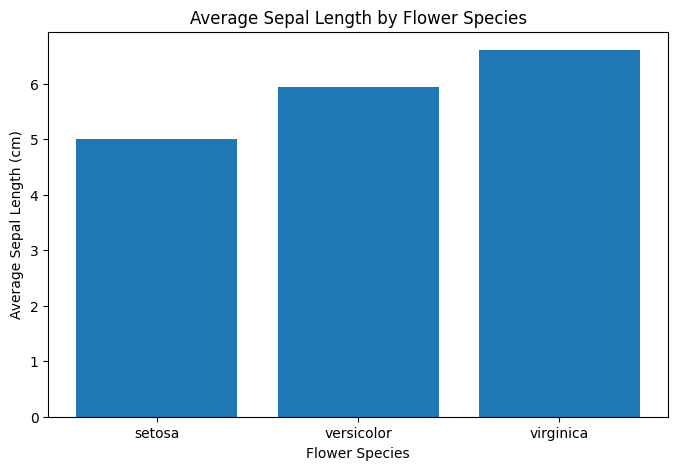

In [7]:
species_avg = df.groupby("species")["sepal length (cm)"].mean()

plt.figure(figsize=(8, 5))
plt.bar(species_avg.index, species_avg.values)

plt.title("Average Sepal Length by Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Average Sepal Length (cm)")
plt.show()

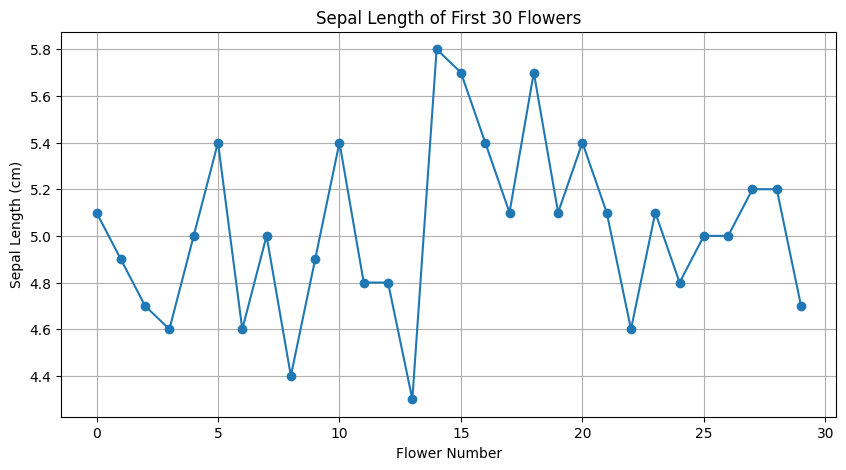

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(df.index[:30], df["sepal length (cm)"].iloc[:30], marker="o")

plt.title("Sepal Length of First 30 Flowers")
plt.xlabel("Flower Number")
plt.ylabel("Sepal Length (cm)")
plt.grid(True)
plt.show()

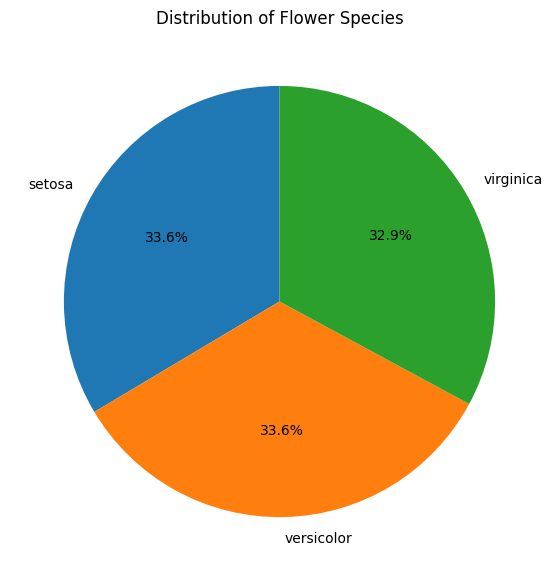

In [9]:
species_count = df["species"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    species_count.values,
    labels=species_count.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Flower Species")
plt.show()

In [ ]:
print("DATA ANALYSIS PROJECT - CONCLUSION")
print("-----------------------------------")

print("1. Dataset: Iris Flower Dataset")
print("2. Total Records:", len(df))
print("3. Total Features:", len(iris.feature_names))
print("4. Flower Species:", df["species"].nunique())

print("\nSpecies Distribution:")
print(df["species"].value_counts())

print("\nConclusion:")
print("The Iris dataset was successfully loaded and explored using Pandas and NumPy.")
print("Missing values and duplicate records were checked and handled.")
print("Statistical analysis was performed.")
print("Bar, line, and pie charts were created using Matplotlib.")

print("\nProject Completed Successfully!")